<a href="https://colab.research.google.com/github/miiiray/banking-intent-ai/blob/main/notebooks/01_veri_inceleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Libraries and datas**

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split  # scikit-learn kütüphanesinden veriyi bölmeye yarayan hazır fonksiyonu alıyoruz

url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/"
# veriyi tablo olarak işlemek için
train = pd.read_csv(url + "train.csv")
test = pd.read_csv(url + "test.csv")
#verileri yükle

print(train.shape, test.shape)
train.head() #ilk 5ini görüntüle



(10003, 2) (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


**Categories**

In [6]:
counts = train["category"].value_counts()

print(counts)
print("Kategori sayısı:", len(counts))

len(counts)
print(train.isnull().sum())
print("Tekrar eden satır:", train.duplicated().sum())


category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64
Kategori sayısı: 77
text        0
category    0
dtype: int64
Tekrar eden satır: 0


**Controls and cleaning**

In [7]:

# standartlaştırma
train_key = train["text"].fillna("").str.lower().str.split().str.join(" ")
test_key = test["text"].fillna("").str.lower().str.split().str.join(" ")

print("Train boş mesaj:", train_key.eq("").sum())
print("Test boş mesaj:", test_key.eq("").sum())

print("\nTest eksik değerler:")
print(test.isnull().sum())

print("\nTrain tekrar eden mesaj:", train_key.duplicated().sum())
print("Test tekrar eden mesaj:", test_key.duplicated().sum())

# Testte de bulunan eğitim satırlarını işaretliyoruz.
overlap = train_key.isin(test_key)

print("\nTestte de bulunan eğitim satırı:", overlap.sum())

temiz = train[~overlap & ~train_key.duplicated()]
print("Önce:", len(train), "Sonra:", len(temiz))


Train boş mesaj: 0
Test boş mesaj: 0

Test eksik değerler:
text        0
category    0
dtype: int64

Train tekrar eden mesaj: 4
Test tekrar eden mesaj: 1

Testte de bulunan eğitim satırı: 7
Önce: 10003 Sonra: 9992


**Diving the data**

In [8]:

# Temizlenmiş train verisini ikiye bölüyoruz:
# train_df -> modelin öğreneceği kısım (%85)
# val_df   -> ayarları seçmek için kullanacağımız deneme sınavı (%15)
train_df, val_df = train_test_split(
    temiz,                          # bölünecek veri: temizlenmiş train tablosu
    test_size=0.15,                 # verinin %15'i validation'a ayrılsın
    stratify=temiz["category"],     # her kategorinin oranı iki parçada da aynı kalsın
    random_state=42                 # bölme her çalıştırmada aynı çıksın (ikimiz de aynı sonucu alalım)
)

# Üç parçanın boyutlarını (satır, sütun) yazdırıp kontrol ediyoruz
print("Train:", train_df.shape)       # model bununla eğitilecek
print("Validation:", val_df.shape)    # ayarlar bununla seçilecek
print("Test:", test.shape)            # final sınavı, sadece en sonda kullanılacak



Train: (8493, 2)
Validation: (1499, 2)
Test: (3080, 2)


**Label Encoding**

In [9]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()                 # isimleri sayıya çeviren araç
encoder.fit(train_df["category"])        # 77 kategoriyi SADECE train'den öğren

y_train = encoder.transform(train_df["category"])   # isim -> sayı
y_val = encoder.transform(val_df["category"])
y_test = encoder.transform(test["category"])

print(train_df["category"].values[:3])   # ilk 3 kategori ismi
print(y_train[:3])                       # karşılık gelen sayılar
print("Sınıf sayısı:", len(encoder.classes_))


['top_up_failed' 'change_pin' 'getting_spare_card']
[59 22 40]
Sınıf sayısı: 77


**Message Length Analysis**

In [10]:
uzunluk = train_df["text"].str.split().str.len()   # her mesajdaki kelime sayısı
print(uzunluk.describe())                          # ortalama, en kısa, en uzun
print("%95'lik değer:", uzunluk.quantile(0.95))    # mesajların %95'i bundan kısa


count    8493.000000
mean       11.982338
std         7.956291
min         2.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text, dtype: float64
%95'lik değer: 30.0


**Tokenization and Padding**

In [11]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

MAX_LEN = 30          # mesajların %95'i 30 kelimeden kısa
MAX_WORDS = 10000     # sözlükte en fazla 10.000 kelime

vectorizer = TextVectorization(
    max_tokens=MAX_WORDS,
    output_sequence_length=MAX_LEN   # kısa olanlara 0 ekle, uzunları kes
)

vectorizer.adapt(train_df["text"].values)   # sözlüğü SADECE train'den oluştur

X_train = vectorizer(train_df["text"].values)
X_val = vectorizer(val_df["text"].values)
X_test = vectorizer(test["text"].values)

print("Sözlükteki kelime sayısı:", len(vectorizer.get_vocabulary()))
print("X_train boyutu:", X_train.shape)
print(train_df["text"].values[0])
print(X_train[0].numpy())

Sözlükteki kelime sayısı: 2301
X_train boyutu: (8493, 30)
I tried again to top up my card after doing it a couple days ago when it had worked. Now, it doesn't seem to be working. Can you tell me what the deal is here please?
[  2  96 448   4  41  25   3   7 174 353  10   5 194 154 128  49  10 196
 378 100  10 223 292   4  39 122  11  17  90  22]


**Training Settings (shared by all models)**

In [12]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)   # rastgelelik sabit: her çalıştırmada aynı sonuç

VOCAB_SIZE = len(vectorizer.get_vocabulary())  # sözlükteki kelime sayısı
NUM_CLASSES = len(encoder.classes_)            # 77 kategori
EMBED_DIM = 128      # her kelimeyi 128 sayılık bir vektörle temsil et
EPOCHS = 30          # en fazla 30 tur eğit
BATCH_SIZE = 32      # model her seferde 32 mesaj görüp kendini güncellesin

print("Sözlük:", VOCAB_SIZE, "| Sınıf:", NUM_CLASSES)


Sözlük: 2301 | Sınıf: 77


**Build the RNN Model**

In [13]:
rnn_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),                 # girdi: 30 sayılık mesaj
    layers.Embedding(VOCAB_SIZE, EMBED_DIM,
                     mask_zero=True),               # kelime -> vektör, 0'ları (padding) yok say
    layers.SimpleRNN(64),                           # 64 birimlik hafıza ile sırayla oku
    layers.Dropout(0.3),                            # eğitimde nöronların %30'unu rastgele kapat
    layers.Dense(NUM_CLASSES, activation="softmax") # 77 kategori için olasılık
])

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 311,885 (1.19 MB)

 Trainable params: 311,885 (1.19 MB)

 Non-trainable params: 0 (0.00 B)

**Compile the Model**

In [14]:
rnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),                         # ağırlıkları güncelleyen yöntem
    loss="sparse_categorical_crossentropy",    # hata ölçüsü
    metrics=["accuracy"]                       # eğitim sırasında doğruluk göster
)

**Train the RNN**

In [15]:
early_stop = EarlyStopping(
    monitor="val_loss",          # validation hatasını izle
    patience=3,                  # 3 epoch boyunca iyileşmezse dur
    restore_best_weights=True    # en iyi epoch'taki modele geri dön
)

start = time.time()              # süre ölçümü başlasın

rnn_history = rnn_model.fit(
    X_train, y_train,                    # çalışma verisi
    validation_data=(X_val, y_val),      # her epoch sonunda deneme sınavı
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

rnn_train_time = time.time() - start
print(f"Eğitim süresi: {rnn_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.1062 - loss: 3.9119 - val_accuracy: 0.2809 - val_loss: 3.2745
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.3835 - loss: 2.6459 - val_accuracy: 0.5337 - val_loss: 2.1201
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5841 - loss: 1.7545 - val_accuracy: 0.6331 - val_loss: 1.5947
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.7045 - loss: 1.2625 - val_accuracy: 0.7031 - val_loss: 1.2620
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.7683 - loss: 0.9815 - val_accuracy: 0.7258 - val_loss: 1.1268
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8053 - loss: 0.8082 - val_accuracy: 0.7345 - val_loss: 1.0586
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8365 - loss: 0.6740 - val_accuracy: 0.7638 - val_loss: 0.9461
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8348 - loss: 0.6474 - val_acc

**Training Curves**

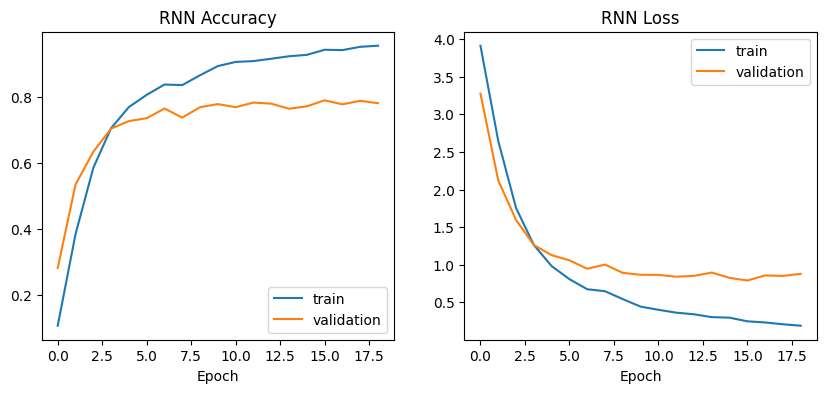

Validation loss: 0.7901
Validation accuracy: %78.85


In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)                                   # sol grafik: doğruluk
plt.plot(rnn_history.history["accuracy"], label="train")
plt.plot(rnn_history.history["val_accuracy"], label="validation")
plt.title("RNN Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                   # sağ grafik: hata
plt.plot(rnn_history.history["loss"], label="train")
plt.plot(rnn_history.history["val_loss"], label="validation")
plt.title("RNN Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

val_loss, val_accuracy = rnn_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: %{val_accuracy * 100:.2f}")

Save to trained model

In [17]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)
rnn_model.save("models/rnn_model.keras")

print("RNN modeli kaydedildi.")

RNN modeli kaydedildi.


Preprocessing information saved

In [18]:
import json

preprocessing = {
    "vocabulary": vectorizer.get_vocabulary(),
    "categories": encoder.classes_.tolist(),
    "max_len": MAX_LEN,
    "max_tokens": MAX_WORDS,
    "standardize": "lower_and_strip_punctuation",
    "split": "whitespace"
}

with open("models/preprocessing.json", "w", encoding="utf-8") as file:
    json.dump(preprocessing, file, ensure_ascii=False, indent=4)

print("Ön işleme bilgileri kaydedildi.")

Ön işleme bilgileri kaydedildi.


**Build the LSTM Model**

In [19]:
tf.keras.utils.set_random_seed(42)   # her model aynı rastgelelikle başlasın (adil karşılaştırma)

lstm_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),                            # girdi: 30 sayılık mesaj
    layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),   # kelime → 128 sayılık vektör
    layers.LSTM(64),                                           # ← RNN'den tek fark burası
    layers.Dropout(0.3),                                       # ezberlemeyi azalt
    layers.Dense(NUM_CLASSES, activation="softmax")            # 77 kategori için olasılık
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,941 (1.33 MB)

 Trainable params: 348,941 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

**Train the LSTM**

In [20]:
early_stop = EarlyStopping(
    monitor="val_loss",          # deneme sınavındaki hatayı izle
    patience=3,                  # 3 epoch iyileşme olmazsa dur
    restore_best_weights=True    # en iyi epoch'a geri dön
)

start = time.time()              # kronometreyi başlat

lstm_history = lstm_model.fit(
    X_train, y_train,                    # çalışma verisi
    validation_data=(X_val, y_val),      # her epoch sonunda deneme sınavı
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

lstm_train_time = time.time() - start    # geçen süre
print(f"LSTM eğitim süresi: {lstm_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.1386 - loss: 3.7592 - val_accuracy: 0.3496 - val_loss: 2.8060
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.4844 - loss: 2.1603 - val_accuracy: 0.6237 - val_loss: 1.6007
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.6901 - loss: 1.2904 - val_accuracy: 0.7418 - val_loss: 1.0736
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.7937 - loss: 0.8724 - val_accuracy: 0.7685 - val_loss: 0.9412
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 16s 60ms/step - accuracy: 0.8501 - loss: 0.6473 - val_accuracy: 0.8065 - val_loss: 0.7453
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.8857 - loss: 0.4975 - val_accuracy: 0.7979 - val_loss: 0.7473
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - accuracy: 0.9075 - loss: 0.4049 - val_accuracy: 0.8232 - val_loss: 0.6589
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.9223 - loss: 0.3408 - val

**LSTM Training Curves**

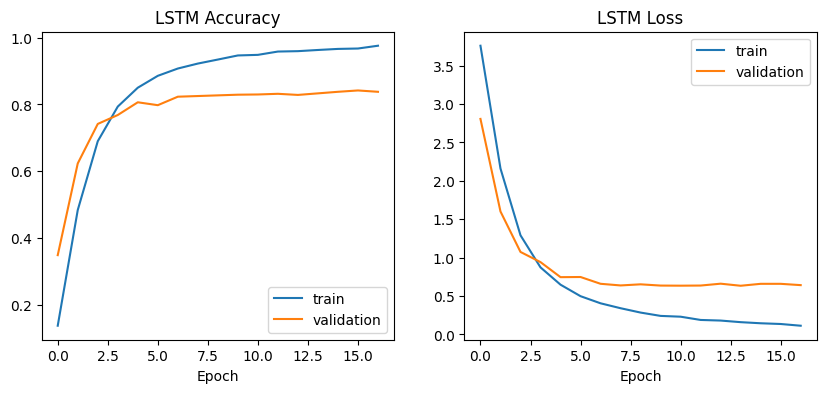

Validation loss: 0.6334
Validation accuracy: %83.32


In [23]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)                                          # sol: doğruluk
plt.plot(lstm_history.history["accuracy"], label="train")
plt.plot(lstm_history.history["val_accuracy"], label="validation")
plt.title("LSTM Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                          # sağ: hata
plt.plot(lstm_history.history["loss"], label="train")
plt.plot(lstm_history.history["val_loss"], label="validation")
plt.title("LSTM Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

val_loss, val_accuracy = lstm_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: %{val_accuracy * 100:.2f}")

Save to trained model

In [24]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

lstm_model.save("models/lstm_model.keras")

print("LSTM modeli kaydedildi.")

LSTM modeli kaydedildi.


Buid the GRU model

In [25]:
tf.keras.utils.set_random_seed(42)  # tekrarlanabilirlik için

gru_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,), dtype="int64"),
    layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
    layers.GRU(64),                         # GRU katmanı
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 336,781 (1.28 MB)

 Trainable params: 336,781 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

train the GRU

In [26]:
early_stop_gru = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

start = time.perf_counter()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_gru],
    shuffle=True
)

gru_train_time = time.perf_counter() - start

print(f"GRU eğitim süresi: {gru_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.1230 - loss: 3.8085 - val_accuracy: 0.3336 - val_loss: 2.9315
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.4455 - loss: 2.2173 - val_accuracy: 0.6024 - val_loss: 1.6673
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.6631 - loss: 1.3442 - val_accuracy: 0.7058 - val_loss: 1.1598
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.7781 - loss: 0.9206 - val_accuracy: 0.7732 - val_loss: 0.9244
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.8388 - loss: 0.6747 - val_accuracy: 0.7992 - val_loss: 0.8022
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.8794 - loss: 0.5317 - val_accuracy: 0.8039 - val_loss: 0.7503
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.8992 - loss: 0.4228 - val_accuracy: 0.8199 - val_loss: 0.6983
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.9176 - loss: 0.3481 - val_acc

GRU training Curves

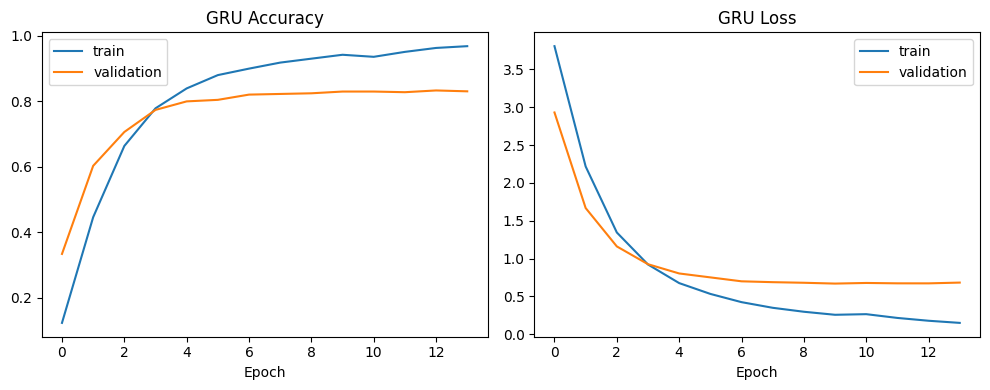

GRU validation loss: 0.6683
GRU validation accuracy: %82.92


In [27]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)  # sol: doğruluk
plt.plot(gru_history.history["accuracy"], label="train")
plt.plot(gru_history.history["val_accuracy"], label="validation")
plt.title("GRU Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)  # sağ: hata
plt.plot(gru_history.history["loss"], label="train")
plt.plot(gru_history.history["val_loss"], label="validation")
plt.title("GRU Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

gru_val_loss, gru_val_accuracy = gru_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"GRU validation loss: {gru_val_loss:.4f}")
print(f"GRU validation accuracy: %{gru_val_accuracy * 100:.2f}")